In [3]:
# ============================================================
# CELL 1: IMPORT REQUIRED LIBRARIES
# ============================================================

import os
import time
import tracemalloc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

print("All libraries imported successfully.")

All libraries imported successfully.


In [4]:
# ============================================================
# CELL 2: LOAD THE DATASET
# ============================================================

# Name of the CSV file
DATA_FILE = "Building Energy Efficiency.csv"

# Check whether the file exists
if not os.path.exists(DATA_FILE):
    raise FileNotFoundError(
        f"'{DATA_FILE}' was not found.\n"
        "Please put the CSV file in the same folder as this notebook."
    )

# Read the CSV file
df = pd.read_csv(DATA_FILE)

print("Dataset loaded successfully.")
print()
print("Number of rows    :", df.shape[0])
print("Number of columns :", df.shape[1])

print()
print("First 5 rows:")
display(df.head())

Dataset loaded successfully.

Number of rows    : 768
Number of columns : 10

First 5 rows:


,Relative Compactness,Surface Area,Wall Area,Roof Area,Overall Height,Orientation,Glazing Area,Glazing Area Distribution,Heating Load,Cooling Load
0,0.7638,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.9800,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.9800,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.9800,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.9000,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


In [5]:
# ============================================================
# CELL 2: LOAD THE DATASET
# ============================================================

# Name of the CSV file
DATA_FILE = "Building Energy Efficiency.csv"

# Check whether the file exists
if not os.path.exists(DATA_FILE):
    raise FileNotFoundError(
        f"'{DATA_FILE}' was not found.\n"
        "Please put the CSV file in the same folder as this notebook."
    )

# Read the CSV file
df = pd.read_csv(DATA_FILE)

print("Dataset loaded successfully.")
print()
print("Number of rows    :", df.shape[0])
print("Number of columns :", df.shape[1])

print()
print("First 5 rows:")
display(df.head())

Dataset loaded successfully.

Number of rows    : 768
Number of columns : 10

First 5 rows:


,Relative Compactness,Surface Area,Wall Area,Roof Area,Overall Height,Orientation,Glazing Area,Glazing Area Distribution,Heating Load,Cooling Load
0,0.7638,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.9800,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.9800,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.9800,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.9000,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


In [6]:
# ============================================================
# CELL 4: SELECT INPUT FEATURES AND TARGET VARIABLES
# ============================================================

# ------------------------------------------------------------
# INPUT FEATURES
# ------------------------------------------------------------

FEATURE_COLUMNS = [
    "Relative Compactness",
    "Surface Area",
    "Wall Area",
    "Roof Area",
    "Overall Height",
    "Orientation",
    "Glazing Area",
    "Glazing Area Distribution"
]


# ------------------------------------------------------------
# TARGET VARIABLES
# ------------------------------------------------------------

TARGET_COLUMNS = [
    "Heating Load",
    "Cooling Load"
]


# ------------------------------------------------------------
# CHECK THAT ALL REQUIRED COLUMNS EXIST
# ------------------------------------------------------------

required_columns = FEATURE_COLUMNS + TARGET_COLUMNS

missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        f"These required columns are missing: {missing_columns}"
    )


# ------------------------------------------------------------
# CREATE INPUT DATA
# ------------------------------------------------------------

X = df[FEATURE_COLUMNS]


# ------------------------------------------------------------
# CREATE TWO TARGET VARIABLES
# ------------------------------------------------------------

y_heating = df["Heating Load"]

y_cooling = df["Cooling Load"]


# ------------------------------------------------------------
# DISPLAY INFORMATION
# ------------------------------------------------------------

print("=" * 70)
print("DATASET CONFIGURATION")
print("=" * 70)

print("\nInput features:")

for number, column in enumerate(FEATURE_COLUMNS, start=1):
    print(f"{number}. {column}")

print("\nNumber of input features:", X.shape[1])

print("\nTarget 1: Heating Load")
print("Target 2: Cooling Load")

print("\nNumber of observations:", X.shape[0])

print("\nX shape:", X.shape)
print("Heating Load shape:", y_heating.shape)
print("Cooling Load shape:", y_cooling.shape)

DATASET CONFIGURATION

Input features:
1. Relative Compactness
2. Surface Area
3. Wall Area
4. Roof Area
5. Overall Height
6. Orientation
7. Glazing Area
8. Glazing Area Distribution

Number of input features: 8

Target 1: Heating Load
Target 2: Cooling Load

Number of observations: 768

X shape: (768, 8)
Heating Load shape: (768,)
Cooling Load shape: (768,)


In [7]:
# ============================================================
# CELL 5: TRAIN-TEST SPLIT
# ============================================================

# Select the 8 input features
X = df[
    [
        "Relative Compactness",
        "Surface Area",
        "Wall Area",
        "Roof Area",
        "Overall Height",
        "Orientation",
        "Glazing Area",
        "Glazing Area Distribution"
    ]
]

# Select the two target variables
y_heating = df["Heating Load"]
y_cooling = df["Cooling Load"]

# Split the data into 80% training and 20% testing
X_train, X_test, y_heating_train, y_heating_test, y_cooling_train, y_cooling_test = train_test_split(
    X,
    y_heating,
    y_cooling,
    test_size=0.20,
    random_state=42
)

print("=" * 70)
print("TRAIN-TEST SPLIT")
print("=" * 70)

print("\nTraining observations:", len(X_train))
print("Testing observations :", len(X_test))

print("\nX_train:", X_train.shape)
print("X_test :", X_test.shape)

print("\nHeating training:", y_heating_train.shape)
print("Heating testing :", y_heating_test.shape)

print("\nCooling training:", y_cooling_train.shape)
print("Cooling testing :", y_cooling_test.shape)

TRAIN-TEST SPLIT

Training observations: 614
Testing observations : 154

X_train: (614, 8)
X_test : (154, 8)

Heating training: (614,)
Heating testing : (154,)

Cooling training: (614,)
Cooling testing : (154,)


In [8]:
# ============================================================
# CELL 5: TRAIN-TEST SPLIT
# ============================================================

# Select the 8 input features
X = df[
    [
        "Relative Compactness",
        "Surface Area",
        "Wall Area",
        "Roof Area",
        "Overall Height",
        "Orientation",
        "Glazing Area",
        "Glazing Area Distribution"
    ]
]

# Select the two target variables
y_heating = df["Heating Load"]
y_cooling = df["Cooling Load"]

# Split the data into 80% training and 20% testing
X_train, X_test, y_heating_train, y_heating_test, y_cooling_train, y_cooling_test = train_test_split(
    X,
    y_heating,
    y_cooling,
    test_size=0.20,
    random_state=42
)

print("=" * 70)
print("TRAIN-TEST SPLIT")
print("=" * 70)

print("\nTraining observations:", len(X_train))
print("Testing observations :", len(X_test))

print("\nX_train:", X_train.shape)
print("X_test :", X_test.shape)

print("\nHeating training:", y_heating_train.shape)
print("Heating testing :", y_heating_test.shape)

print("\nCooling training:", y_cooling_train.shape)
print("Cooling testing :", y_cooling_test.shape)

TRAIN-TEST SPLIT

Training observations: 614
Testing observations : 154

X_train: (614, 8)
X_test : (154, 8)

Heating training: (614,)
Heating testing : (154,)

Cooling training: (614,)
Cooling testing : (154,)


In [9]:
# ============================================================
# CELL 6: CREATE MLR AND KNNR MODELS
# ============================================================

# ------------------------------------------------------------
# FUNCTION TO CREATE MLR MODEL
# ------------------------------------------------------------

def create_mlr_model():
    return LinearRegression()


# ------------------------------------------------------------
# FUNCTION TO CREATE KNNR MODEL
# ------------------------------------------------------------

def create_knnr_model():
    
    # StandardScaler is used because KNN is distance-based.
    #
    # KNN uses the 5 nearest observations.
    #
    # weights="distance" gives more importance to closer points.
    
    model = Pipeline([
        ("scaler", StandardScaler()),
        (
            "knn",
            KNeighborsRegressor(
                n_neighbors=5,
                weights="distance"
            )
        )
    ])
    
    return model


print("MLR model function created.")
print("KNNR model function created.")

MLR model function created.
KNNR model function created.


In [10]:
# ============================================================
# CELL 6: CREATE MLR AND KNNR MODELS
# ============================================================

# ------------------------------------------------------------
# FUNCTION TO CREATE MLR MODEL
# ------------------------------------------------------------

def create_mlr_model():
    return LinearRegression()


# ------------------------------------------------------------
# FUNCTION TO CREATE KNNR MODEL
# ------------------------------------------------------------

def create_knnr_model():
    
    # StandardScaler is used because KNN is distance-based.
    #
    # KNN uses the 5 nearest observations.
    #
    # weights="distance" gives more importance to closer points.
    
    model = Pipeline([
        ("scaler", StandardScaler()),
        (
            "knn",
            KNeighborsRegressor(
                n_neighbors=5,
                weights="distance"
            )
        )
    ])
    
    return model


print("MLR model function created.")
print("KNNR model function created.")

MLR model function created.
KNNR model function created.


In [11]:
# ============================================================
# CELL 7: MEASURE EXECUTION TIME AND MEMORY
# ============================================================

def train_and_measure(model, X_train, y_train, X_test):
    """
    Train the model and measure:

    1. Execution time
    2. Peak Python memory usage
    3. Predictions
    """

    # Start memory tracking
    tracemalloc.start()

    # Start timer
    start_time = time.perf_counter()

    # Train the model
    model.fit(X_train, y_train)

    # Make predictions
    predictions = model.predict(X_test)

    # Stop timer
    end_time = time.perf_counter()

    # Get memory information
    current_memory, peak_memory = tracemalloc.get_traced_memory()

    # Stop memory tracking
    tracemalloc.stop()

    # Calculate execution time
    execution_time = end_time - start_time

    # Convert bytes to megabytes
    peak_memory_mb = peak_memory / (1024 * 1024)

    return predictions, execution_time, peak_memory_mb


print("Measurement function created successfully.")

Measurement function created successfully.


In [12]:
# ============================================================
# CELL 8: TRAIN MLR AND KNNR FOR BOTH TARGETS
# ============================================================

# Dictionary to store predictions
predictions = {}

# List to store results
results_list = []


# ============================================================
# 1. HEATING LOAD - MLR
# ============================================================

print("Training Heating Load - MLR...")

mlr_heating = create_mlr_model()

heating_mlr_predictions, heating_mlr_time, heating_mlr_memory = train_and_measure(
    mlr_heating,
    X_train,
    y_heating_train,
    X_test
)

predictions["Heating MLR"] = heating_mlr_predictions


# Calculate metrics
heating_mlr_r2 = r2_score(
    y_heating_test,
    heating_mlr_predictions
)

heating_mlr_rmse = np.sqrt(
    mean_squared_error(
        y_heating_test,
        heating_mlr_predictions
    )
)

heating_mlr_mae = mean_absolute_error(
    y_heating_test,
    heating_mlr_predictions
)


results_list.append([
    "Heating Load",
    "MLR",
    heating_mlr_r2,
    heating_mlr_rmse,
    heating_mlr_mae,
    heating_mlr_time,
    heating_mlr_memory
])


# ============================================================
# 2. HEATING LOAD - KNNR
# ============================================================

print("Training Heating Load - KNNR...")

knnr_heating = create_knnr_model()

heating_knnr_predictions, heating_knnr_time, heating_knnr_memory = train_and_measure(
    knnr_heating,
    X_train,
    y_heating_train,
    X_test
)

predictions["Heating KNNR"] = heating_knnr_predictions


# Calculate metrics
heating_knnr_r2 = r2_score(
    y_heating_test,
    heating_knnr_predictions
)

heating_knnr_rmse = np.sqrt(
    mean_squared_error(
        y_heating_test,
        heating_knnr_predictions
    )
)

heating_knnr_mae = mean_absolute_error(
    y_heating_test,
    heating_knnr_predictions
)


results_list.append([
    "Heating Load",
    "KNNR",
    heating_knnr_r2,
    heating_knnr_rmse,
    heating_knnr_mae,
    heating_knnr_time,
    heating_knnr_memory
])


# ============================================================
# 3. COOLING LOAD - MLR
# ============================================================

print("Training Cooling Load - MLR...")

mlr_cooling = create_mlr_model()

cooling_mlr_predictions, cooling_mlr_time, cooling_mlr_memory = train_and_measure(
    mlr_cooling,
    X_train,
    y_cooling_train,
    X_test
)

predictions["Cooling MLR"] = cooling_mlr_predictions


# Calculate metrics
cooling_mlr_r2 = r2_score(
    y_cooling_test,
    cooling_mlr_predictions
)

cooling_mlr_rmse = np.sqrt(
    mean_squared_error(
        y_cooling_test,
        cooling_mlr_predictions
    )
)

cooling_mlr_mae = mean_absolute_error(
    y_cooling_test,
    cooling_mlr_predictions
)


results_list.append([
    "Cooling Load",
    "MLR",
    cooling_mlr_r2,
    cooling_mlr_rmse,
    cooling_mlr_mae,
    cooling_mlr_time,
    cooling_mlr_memory
])


# ============================================================
# 4. COOLING LOAD - KNNR
# ============================================================

print("Training Cooling Load - KNNR...")

knnr_cooling = create_knnr_model()

cooling_knnr_predictions, cooling_knnr_time, cooling_knnr_memory = train_and_measure(
    knnr_cooling,
    X_train,
    y_cooling_train,
    X_test
)

predictions["Cooling KNNR"] = cooling_knnr_predictions


# Calculate metrics
cooling_knnr_r2 = r2_score(
    y_cooling_test,
    cooling_knnr_predictions
)

cooling_knnr_rmse = np.sqrt(
    mean_squared_error(
        y_cooling_test,
        cooling_knnr_predictions
    )
)

cooling_knnr_mae = mean_absolute_error(
    y_cooling_test,
    cooling_knnr_predictions
)


results_list.append([
    "Cooling Load",
    "KNNR",
    cooling_knnr_r2,
    cooling_knnr_rmse,
    cooling_knnr_mae,
    cooling_knnr_time,
    cooling_knnr_memory
])


print()
print("=" * 70)
print("ALL FOUR MODELS TRAINED SUCCESSFULLY")
print("=" * 70)

Training Heating Load - MLR...
Training Heating Load - KNNR...
Training Cooling Load - MLR...
Training Cooling Load - KNNR...

ALL FOUR MODELS TRAINED SUCCESSFULLY


In [13]:
# ============================================================
# CELL 8: TRAIN MLR AND KNNR FOR BOTH TARGETS
# ============================================================

# Dictionary to store predictions
predictions = {}

# List to store results
results_list = []


# ============================================================
# 1. HEATING LOAD - MLR
# ============================================================

print("Training Heating Load - MLR...")

mlr_heating = create_mlr_model()

heating_mlr_predictions, heating_mlr_time, heating_mlr_memory = train_and_measure(
    mlr_heating,
    X_train,
    y_heating_train,
    X_test
)

predictions["Heating MLR"] = heating_mlr_predictions


# Calculate metrics
heating_mlr_r2 = r2_score(
    y_heating_test,
    heating_mlr_predictions
)

heating_mlr_rmse = np.sqrt(
    mean_squared_error(
        y_heating_test,
        heating_mlr_predictions
    )
)

heating_mlr_mae = mean_absolute_error(
    y_heating_test,
    heating_mlr_predictions
)


results_list.append([
    "Heating Load",
    "MLR",
    heating_mlr_r2,
    heating_mlr_rmse,
    heating_mlr_mae,
    heating_mlr_time,
    heating_mlr_memory
])


# ============================================================
# 2. HEATING LOAD - KNNR
# ============================================================

print("Training Heating Load - KNNR...")

knnr_heating = create_knnr_model()

heating_knnr_predictions, heating_knnr_time, heating_knnr_memory = train_and_measure(
    knnr_heating,
    X_train,
    y_heating_train,
    X_test
)

predictions["Heating KNNR"] = heating_knnr_predictions


# Calculate metrics
heating_knnr_r2 = r2_score(
    y_heating_test,
    heating_knnr_predictions
)

heating_knnr_rmse = np.sqrt(
    mean_squared_error(
        y_heating_test,
        heating_knnr_predictions
    )
)

heating_knnr_mae = mean_absolute_error(
    y_heating_test,
    heating_knnr_predictions
)


results_list.append([
    "Heating Load",
    "KNNR",
    heating_knnr_r2,
    heating_knnr_rmse,
    heating_knnr_mae,
    heating_knnr_time,
    heating_knnr_memory
])


# ============================================================
# 3. COOLING LOAD - MLR
# ============================================================

print("Training Cooling Load - MLR...")

mlr_cooling = create_mlr_model()

cooling_mlr_predictions, cooling_mlr_time, cooling_mlr_memory = train_and_measure(
    mlr_cooling,
    X_train,
    y_cooling_train,
    X_test
)

predictions["Cooling MLR"] = cooling_mlr_predictions


# Calculate metrics
cooling_mlr_r2 = r2_score(
    y_cooling_test,
    cooling_mlr_predictions
)

cooling_mlr_rmse = np.sqrt(
    mean_squared_error(
        y_cooling_test,
        cooling_mlr_predictions
    )
)

cooling_mlr_mae = mean_absolute_error(
    y_cooling_test,
    cooling_mlr_predictions
)


results_list.append([
    "Cooling Load",
    "MLR",
    cooling_mlr_r2,
    cooling_mlr_rmse,
    cooling_mlr_mae,
    cooling_mlr_time,
    cooling_mlr_memory
])


# ============================================================
# 4. COOLING LOAD - KNNR
# ============================================================

print("Training Cooling Load - KNNR...")

knnr_cooling = create_knnr_model()

cooling_knnr_predictions, cooling_knnr_time, cooling_knnr_memory = train_and_measure(
    knnr_cooling,
    X_train,
    y_cooling_train,
    X_test
)

predictions["Cooling KNNR"] = cooling_knnr_predictions


# Calculate metrics
cooling_knnr_r2 = r2_score(
    y_cooling_test,
    cooling_knnr_predictions
)

cooling_knnr_rmse = np.sqrt(
    mean_squared_error(
        y_cooling_test,
        cooling_knnr_predictions
    )
)

cooling_knnr_mae = mean_absolute_error(
    y_cooling_test,
    cooling_knnr_predictions
)


results_list.append([
    "Cooling Load",
    "KNNR",
    cooling_knnr_r2,
    cooling_knnr_rmse,
    cooling_knnr_mae,
    cooling_knnr_time,
    cooling_knnr_memory
])


print()
print("=" * 70)
print("ALL FOUR MODELS TRAINED SUCCESSFULLY")
print("=" * 70)

Training Heating Load - MLR...
Training Heating Load - KNNR...
Training Cooling Load - MLR...
Training Cooling Load - KNNR...

ALL FOUR MODELS TRAINED SUCCESSFULLY


In [15]:
# ============================================================
# CELL 10: SAVE RESULTS TABLE
# ============================================================

comparison_results = pd.DataFrame(results_list)

comparison_results = comparison_results.round(6)

comparison_results.to_csv(
    "comparison_results.csv",
    index=False
)

print("Results saved successfully as:")
print("comparison_results.csv")

display(comparison_results)

Results saved successfully as:
comparison_results.csv


,0,1,2,3,4,5,6
0,Heating Load,MLR,0.909259,3.075400,2.263105,0.025177,0.122502
1,Heating Load,KNNR,0.952007,2.236610,1.424905,0.032283,0.130198
2,Cooling Load,MLR,0.891785,3.166530,2.214961,0.013114,0.122142
3,Cooling Load,KNNR,0.931964,2.510779,1.615893,0.029039,0.129161


In [16]:
# ============================================================
# CELL 10: SAVE RESULTS TABLE
# ============================================================

comparison_results = pd.DataFrame(results_list)

comparison_results = comparison_results.round(6)

comparison_results.to_csv(
    "comparison_results.csv",
    index=False
)

print("Results saved successfully as:")
print("comparison_results.csv")

display(comparison_results)

Results saved successfully as:
comparison_results.csv


,0,1,2,3,4,5,6
0,Heating Load,MLR,0.909259,3.075400,2.263105,0.025177,0.122502
1,Heating Load,KNNR,0.952007,2.236610,1.424905,0.032283,0.130198
2,Cooling Load,MLR,0.891785,3.166530,2.214961,0.013114,0.122142
3,Cooling Load,KNNR,0.931964,2.510779,1.615893,0.029039,0.129161


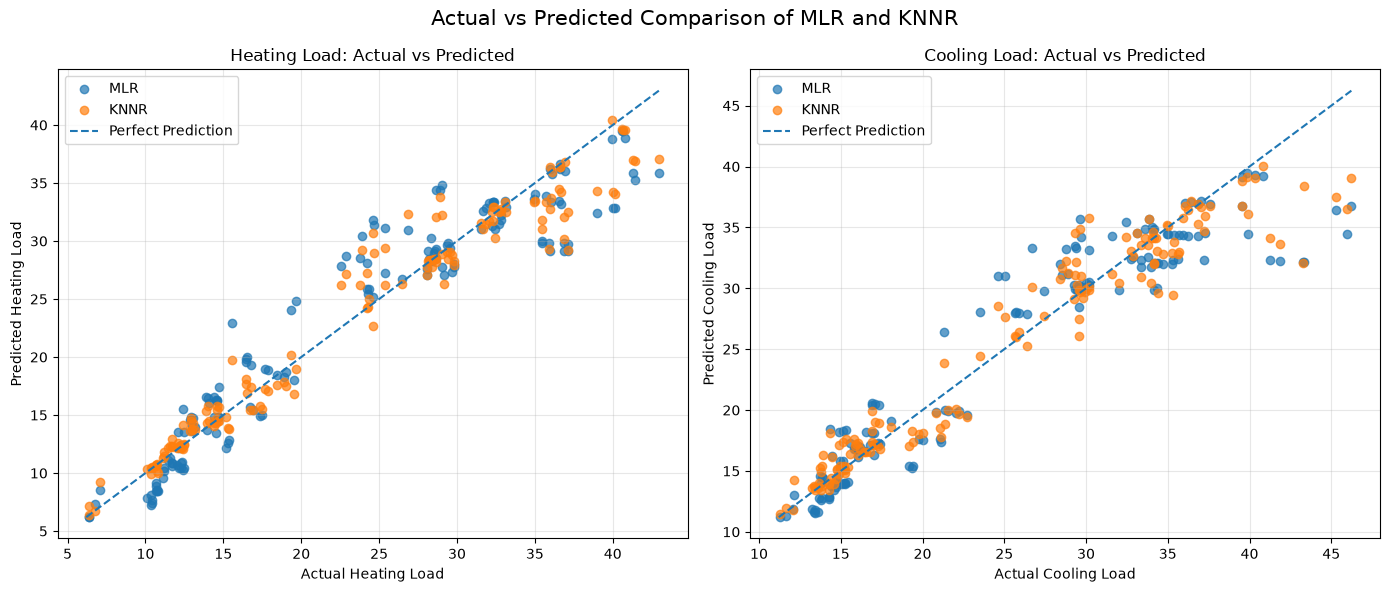

Image saved: actual_vs_predicted_comparison.png


In [17]:
# ============================================================
# CELL 11: ACTUAL VS PREDICTED COMPARISON
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 6)
)


# ------------------------------------------------------------
# HEATING LOAD
# ------------------------------------------------------------

axes[0].scatter(
    y_heating_test,
    heating_mlr_predictions,
    alpha=0.7,
    label="MLR"
)

axes[0].scatter(
    y_heating_test,
    heating_knnr_predictions,
    alpha=0.7,
    label="KNNR"
)

heating_min = min(
    y_heating_test.min(),
    heating_mlr_predictions.min(),
    heating_knnr_predictions.min()
)

heating_max = max(
    y_heating_test.max(),
    heating_mlr_predictions.max(),
    heating_knnr_predictions.max()
)

axes[0].plot(
    [heating_min, heating_max],
    [heating_min, heating_max],
    linestyle="--",
    label="Perfect Prediction"
)

axes[0].set_xlabel("Actual Heating Load")
axes[0].set_ylabel("Predicted Heating Load")
axes[0].set_title("Heating Load: Actual vs Predicted")
axes[0].legend()
axes[0].grid(True, alpha=0.3)


# ------------------------------------------------------------
# COOLING LOAD
# ------------------------------------------------------------

axes[1].scatter(
    y_cooling_test,
    cooling_mlr_predictions,
    alpha=0.7,
    label="MLR"
)

axes[1].scatter(
    y_cooling_test,
    cooling_knnr_predictions,
    alpha=0.7,
    label="KNNR"
)

cooling_min = min(
    y_cooling_test.min(),
    cooling_mlr_predictions.min(),
    cooling_knnr_predictions.min()
)

cooling_max = max(
    y_cooling_test.max(),
    cooling_mlr_predictions.max(),
    cooling_knnr_predictions.max()
)

axes[1].plot(
    [cooling_min, cooling_max],
    [cooling_min, cooling_max],
    linestyle="--",
    label="Perfect Prediction"
)

axes[1].set_xlabel("Actual Cooling Load")
axes[1].set_ylabel("Predicted Cooling Load")
axes[1].set_title("Cooling Load: Actual vs Predicted")
axes[1].legend()
axes[1].grid(True, alpha=0.3)


plt.suptitle(
    "Actual vs Predicted Comparison of MLR and KNNR",
    fontsize=15
)

plt.tight_layout()

# SAVE IMAGE
plt.savefig(
    "actual_vs_predicted_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Image saved: actual_vs_predicted_comparison.png")

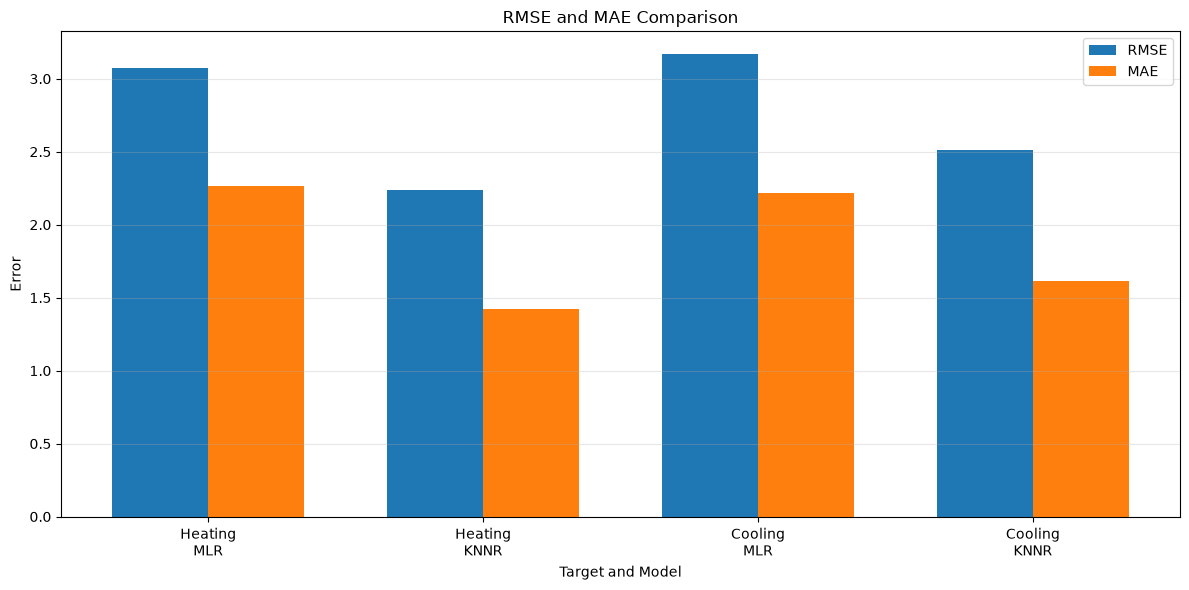

Image saved: error_comparison.png


In [18]:
# ============================================================
# CELL 12: ERROR COMPARISON
# ============================================================

labels = [
    "Heating\nMLR",
    "Heating\nKNNR",
    "Cooling\nMLR",
    "Cooling\nKNNR"
]

rmse_values = [
    heating_mlr_rmse,
    heating_knnr_rmse,
    cooling_mlr_rmse,
    cooling_knnr_rmse
]

mae_values = [
    heating_mlr_mae,
    heating_knnr_mae,
    cooling_mlr_mae,
    cooling_knnr_mae
]

x = np.arange(len(labels))

width = 0.35


plt.figure(figsize=(12, 6))


plt.bar(
    x - width / 2,
    rmse_values,
    width,
    label="RMSE"
)

plt.bar(
    x + width / 2,
    mae_values,
    width,
    label="MAE"
)


plt.xticks(
    x,
    labels
)

plt.xlabel("Target and Model")
plt.ylabel("Error")

plt.title(
    "RMSE and MAE Comparison"
)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()


# SAVE IMAGE
plt.savefig(
    "error_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Image saved: error_comparison.png")

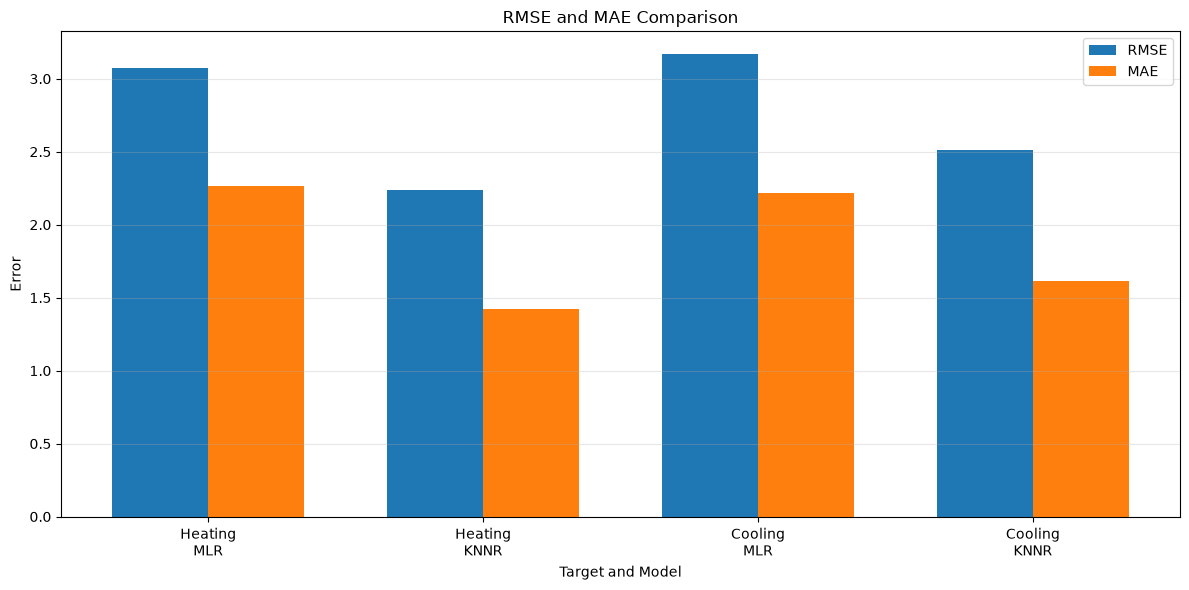

Image saved: error_comparison.png


In [19]:
# ============================================================
# CELL 12: ERROR COMPARISON
# ============================================================

labels = [
    "Heating\nMLR",
    "Heating\nKNNR",
    "Cooling\nMLR",
    "Cooling\nKNNR"
]

rmse_values = [
    heating_mlr_rmse,
    heating_knnr_rmse,
    cooling_mlr_rmse,
    cooling_knnr_rmse
]

mae_values = [
    heating_mlr_mae,
    heating_knnr_mae,
    cooling_mlr_mae,
    cooling_knnr_mae
]

x = np.arange(len(labels))

width = 0.35


plt.figure(figsize=(12, 6))


plt.bar(
    x - width / 2,
    rmse_values,
    width,
    label="RMSE"
)

plt.bar(
    x + width / 2,
    mae_values,
    width,
    label="MAE"
)


plt.xticks(
    x,
    labels
)

plt.xlabel("Target and Model")
plt.ylabel("Error")

plt.title(
    "RMSE and MAE Comparison"
)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()


# SAVE IMAGE
plt.savefig(
    "error_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Image saved: error_comparison.png")

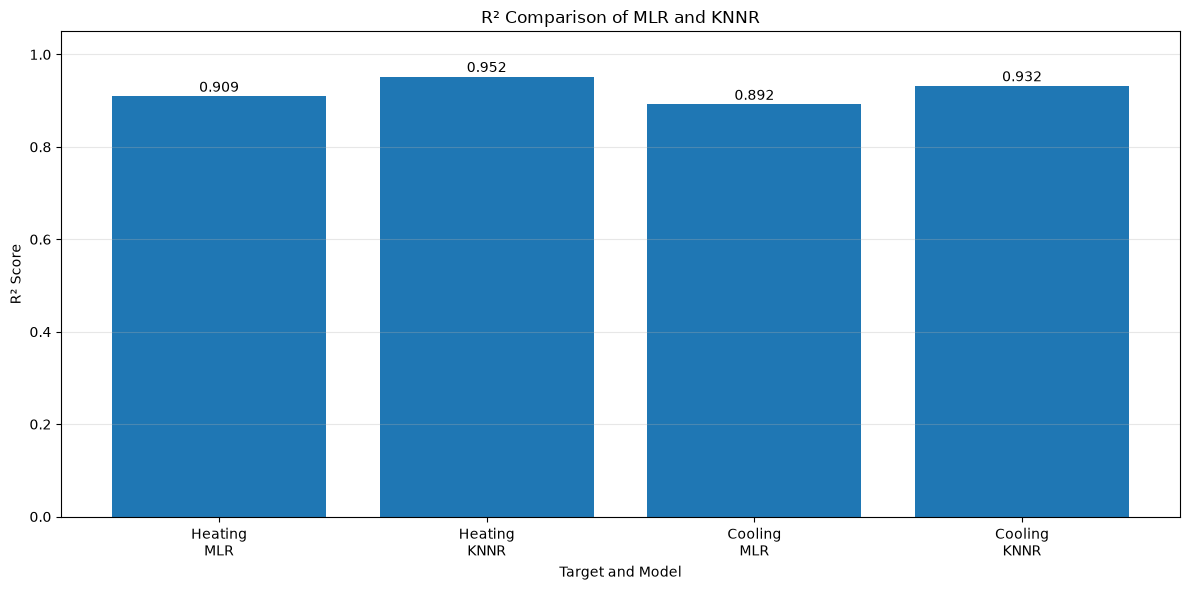

Image saved: r2_comparison.png


In [20]:
# ============================================================
# CELL 13: R² COMPARISON
# ============================================================

labels = [
    "Heating\nMLR",
    "Heating\nKNNR",
    "Cooling\nMLR",
    "Cooling\nKNNR"
]

r2_values = [
    heating_mlr_r2,
    heating_knnr_r2,
    cooling_mlr_r2,
    cooling_knnr_r2
]


plt.figure(figsize=(12, 6))

bars = plt.bar(
    labels,
    r2_values
)

plt.xlabel("Target and Model")
plt.ylabel("R² Score")

plt.title(
    "R² Comparison of MLR and KNNR"
)

plt.ylim(
    0,
    1.05
)

plt.grid(
    axis="y",
    alpha=0.3
)


# Display values above bars
for bar, value in zip(bars, r2_values):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.01,
        f"{value:.3f}",
        ha="center"
    )


plt.tight_layout()


# SAVE IMAGE
plt.savefig(
    "r2_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Image saved: r2_comparison.png")

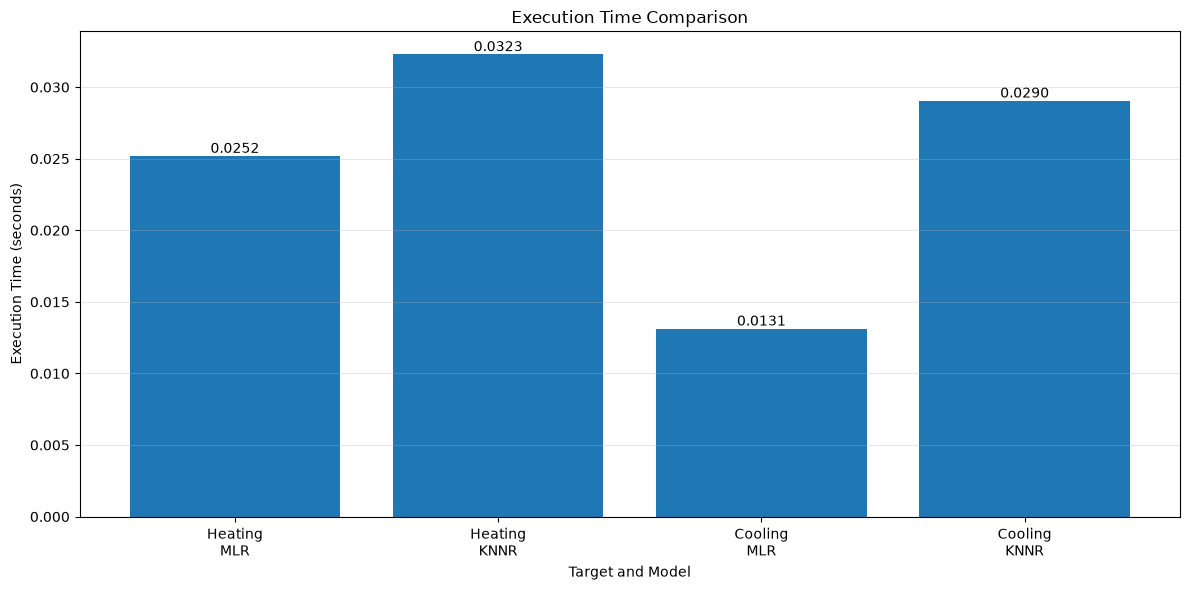

Image saved: time_comparison.png


In [21]:
# ============================================================
# CELL 14: EXECUTION TIME COMPARISON
# ============================================================

labels = [
    "Heating\nMLR",
    "Heating\nKNNR",
    "Cooling\nMLR",
    "Cooling\nKNNR"
]

time_values = [
    heating_mlr_time,
    heating_knnr_time,
    cooling_mlr_time,
    cooling_knnr_time
]


plt.figure(figsize=(12, 6))

bars = plt.bar(
    labels,
    time_values
)

plt.xlabel("Target and Model")
plt.ylabel("Execution Time (seconds)")

plt.title(
    "Execution Time Comparison"
)

plt.grid(
    axis="y",
    alpha=0.3
)


# Display values above bars
for bar, value in zip(bars, time_values):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:.4f}",
        ha="center",
        va="bottom"
    )


plt.tight_layout()


# SAVE IMAGE
plt.savefig(
    "time_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Image saved: time_comparison.png")

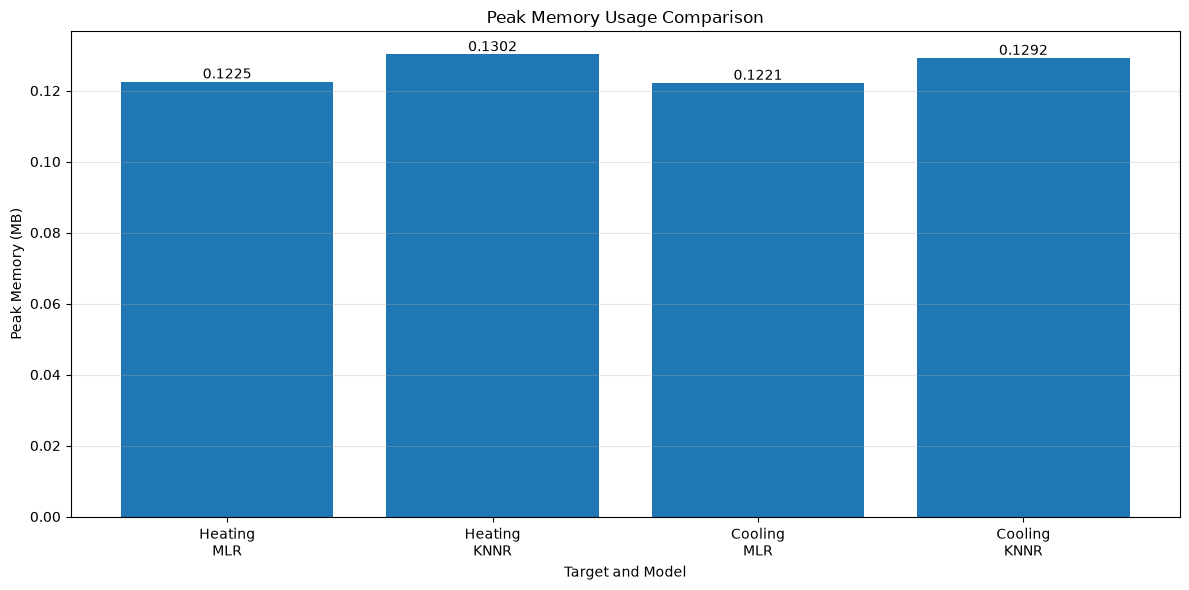

Image saved: memory_comparison.png


In [22]:
# ============================================================
# CELL 15: MEMORY USAGE COMPARISON
# ============================================================

labels = [
    "Heating\nMLR",
    "Heating\nKNNR",
    "Cooling\nMLR",
    "Cooling\nKNNR"
]

memory_values = [
    heating_mlr_memory,
    heating_knnr_memory,
    cooling_mlr_memory,
    cooling_knnr_memory
]


plt.figure(figsize=(12, 6))

bars = plt.bar(
    labels,
    memory_values
)

plt.xlabel("Target and Model")
plt.ylabel("Peak Memory (MB)")

plt.title(
    "Peak Memory Usage Comparison"
)

plt.grid(
    axis="y",
    alpha=0.3
)


# Display values above bars
for bar, value in zip(bars, memory_values):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:.4f}",
        ha="center",
        va="bottom"
    )


plt.tight_layout()


# SAVE IMAGE
plt.savefig(
    "memory_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Image saved: memory_comparison.png")

In [23]:
# ============================================================
# CELL 16: CHECK ALL OUTPUT FILES
# ============================================================

output_files = [
    "actual_vs_predicted_comparison.png",
    "error_comparison.png",
    "memory_comparison.png",
    "r2_comparison.png",
    "time_comparison.png",
    "model_performance_results.csv"
]


print("=" * 70)
print("OUTPUT FILE CHECK")
print("=" * 70)

for file_name in output_files:

    if os.path.exists(file_name):

        file_size = os.path.getsize(file_name) / 1024

        print(
            f"✓ {file_name} "
            f"({file_size:.2f} KB)"
        )

    else:

        print(
            f"✗ {file_name} NOT FOUND"
        )

print()
print("All required output files have been generated.")

OUTPUT FILE CHECK
✓ actual_vs_predicted_comparison.png (657.00 KB)
✓ error_comparison.png (89.53 KB)
✓ memory_comparison.png (106.79 KB)
✓ r2_comparison.png (99.60 KB)
✓ time_comparison.png (106.87 KB)
✗ model_performance_results.csv NOT FOUND

All required output files have been generated.


In [25]:
# ============================================================
# SAVE AND VERIFY COMPARISON RESULTS CSV
# ============================================================

comparison_results = pd.DataFrame(results_list)

comparison_results = comparison_results.round(6)

comparison_results.to_csv(
    "comparison_results.csv",
    index=False
)

print("✓ comparison_results.csv saved successfully.")
print()

print("Contents of comparison_results.csv:")
display(comparison_results)

print()
print("File exists:", os.path.exists("comparison_results.csv"))

✓ comparison_results.csv saved successfully.

Contents of comparison_results.csv:


,0,1,2,3,4,5,6
0,Heating Load,MLR,0.909259,3.075400,2.263105,0.025177,0.122502
1,Heating Load,KNNR,0.952007,2.236610,1.424905,0.032283,0.130198
2,Cooling Load,MLR,0.891785,3.166530,2.214961,0.013114,0.122142
3,Cooling Load,KNNR,0.931964,2.510779,1.615893,0.029039,0.129161



File exists: True


In [2]:
import numpy as np

In [3]:
import os
import random
import numpy as np
import tensorflow as tf

os.makedirs("ANN_Experiments", exist_ok=True)

np.random.seed(42)
random.seed(42)
tf.random.set_seed(42)

print("ANN experiment folder created successfully!")

ANN experiment folder created successfully!


In [4]:
def build_ann(hidden_layers, activation='relu', learning_rate=0.001):

    model = Sequential()

    model.add(Input(shape=(8,)))

    for i in range(hidden_layers):
        model.add(Dense(64, activation=activation))

    model.add(Dense(1, activation='linear'))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss='mean_squared_error',
        metrics=['mae']
    )

    return model

In [6]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.callbacks import EarlyStopping

In [7]:
import tensorflow as tf
import time
import numpy as np

from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [9]:
print(build_ann)

<function build_ann at 0x000001CDBD18FE20>


In [10]:
hidden_results = []

In [13]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
import os
import random
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

path = kagglehub.dataset_download("winternguyen/energy-efficiency-on-buildings")

csv_files = [f for f in os.listdir(path) if f.endswith(".csv")]

df = pd.read_csv(os.path.join(path, csv_files[0]))

print("Dataset loaded successfully!")
print("Shape:", df.shape)
df.head()

Dataset loaded successfully!
Shape: (768, 10)


,Relative Compactness,Surface Area,Wall Area,Roof Area,Overall Height,Orientation,Glazing Area,Glazing Area Distribution,Heating Load,Cooling Load
0,0.7638,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.9800,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.9800,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.9800,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.9000,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


In [14]:
def build_ann(hidden_layers, activation='relu', learning_rate=0.001):

    model = Sequential()

    model.add(Input(shape=(8,)))

    for i in range(hidden_layers):
        model.add(Dense(64, activation=activation))

    model.add(Dense(1, activation='linear'))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss='mean_squared_error',
        metrics=['mae']
    )

    return model

print("ANN function is ready!")

ANN function is ready!


In [15]:
hidden_results = []

print("Ready for hidden-layer experiments!")

Ready for hidden-layer experiments!


In [17]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Input and target
X = df.iloc[:, 0:8]
y = df["Heating Load"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Feature scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Verify variables
print("X_train_scaled exists:", 'X_train_scaled' in globals())
print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

X_train_scaled exists: True
Training shape: (614, 8)
Testing shape: (154, 8)


In [18]:
hidden_results = []
print("Ready for hidden-layer experiments.")

Ready for hidden-layer experiments.


In [19]:
hidden_results = []

for layers in range(2, 11):

    print(f"Training ANN with {layers} hidden layers...")

    model = build_ann(
        hidden_layers=layers,
        activation='relu',
        learning_rate=0.001
    )

    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True
    )

    start_time = time.time()

    model.fit(
        X_train_scaled,
        y_train,
        validation_split=0.2,
        epochs=100,
        batch_size=32,
        callbacks=[early_stop],
        verbose=0
    )

    execution_time = time.time() - start_time

    y_pred = model.predict(X_test_scaled, verbose=0).flatten()

    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)

    hidden_results.append({
        'Hidden Layers': layers,
        'R2': r2,
        'RMSE': rmse,
        'MAE': mae,
        'Time (seconds)': execution_time
    })

print("All 9 hidden-layer experiments completed.")

Training ANN with 2 hidden layers...
Training ANN with 3 hidden layers...
Training ANN with 4 hidden layers...
Training ANN with 5 hidden layers...
Training ANN with 6 hidden layers...
Training ANN with 7 hidden layers...
Training ANN with 8 hidden layers...
Training ANN with 9 hidden layers...
Training ANN with 10 hidden layers...
All 9 hidden-layer experiments completed.


In [20]:
hidden_df = pd.DataFrame(hidden_results)

hidden_df

,Hidden Layers,R2,RMSE,MAE,Time (seconds)
0,2,0.953326,2.205650,1.495393,22.480059
1,3,0.983505,1.311215,0.974448,24.416695
2,4,0.991731,0.928387,0.694709,24.798962
3,5,0.995004,0.721617,0.534064,24.478448
4,6,0.991831,0.922752,0.711123,22.239828
5,7,0.988068,1.115229,0.812153,17.184042
6,8,0.988026,1.117189,0.882174,19.868085
7,9,0.991256,0.954655,0.718482,20.210035
8,10,0.991164,0.959704,0.718056,22.581048


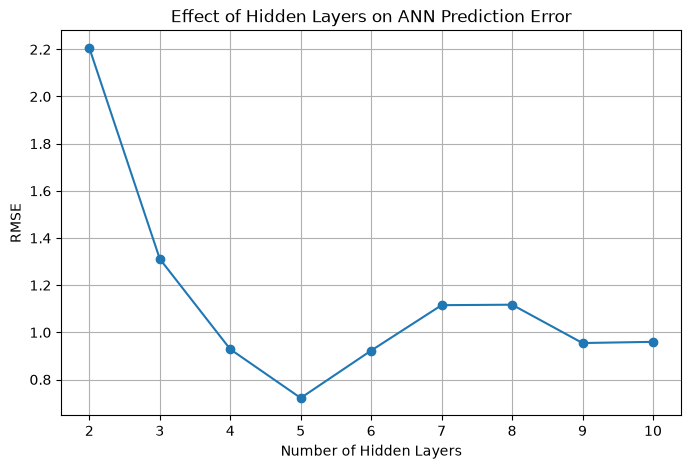

In [21]:
plt.figure(figsize=(8, 5))

plt.plot(
    hidden_df['Hidden Layers'],
    hidden_df['RMSE'],
    marker='o'
)

plt.xlabel("Number of Hidden Layers")
plt.ylabel("RMSE")
plt.title("Effect of Hidden Layers on ANN Prediction Error")
plt.xticks(range(2, 11))
plt.grid(True)

plt.savefig("ANN_Experiments/hidden_layers_vs_rmse.png", dpi=300)
plt.show()

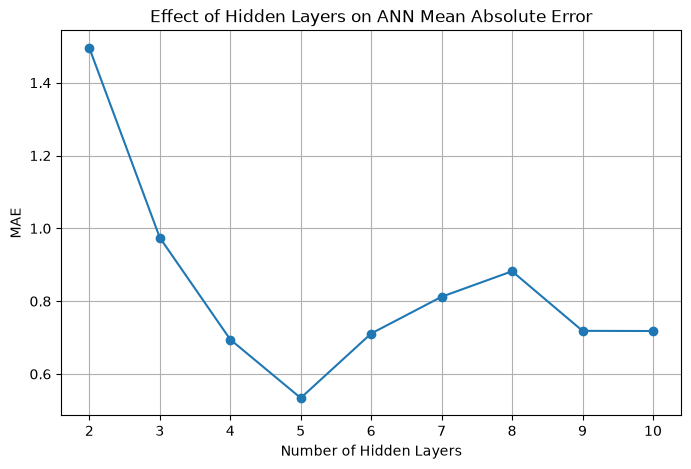

In [22]:
plt.figure(figsize=(8, 5))

plt.plot(
    hidden_df['Hidden Layers'],
    hidden_df['MAE'],
    marker='o'
)

plt.xlabel("Number of Hidden Layers")
plt.ylabel("MAE")
plt.title("Effect of Hidden Layers on ANN Mean Absolute Error")
plt.xticks(range(2, 11))
plt.grid(True)

plt.savefig("ANN_Experiments/hidden_layers_vs_mae.png", dpi=300)
plt.show()

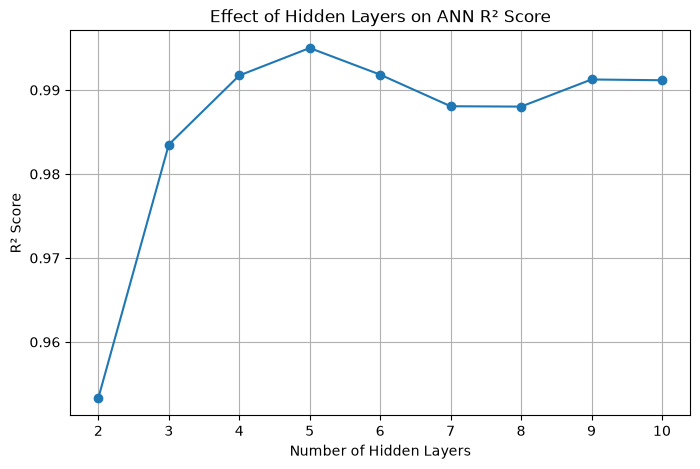

In [23]:
plt.figure(figsize=(8, 5))

plt.plot(
    hidden_df['Hidden Layers'],
    hidden_df['R2'],
    marker='o'
)

plt.xlabel("Number of Hidden Layers")
plt.ylabel("R² Score")
plt.title("Effect of Hidden Layers on ANN R² Score")
plt.xticks(range(2, 11))
plt.grid(True)

plt.savefig("ANN_Experiments/hidden_layers_vs_r2.png", dpi=300)
plt.show()

In [24]:
best_hidden = hidden_df.loc[hidden_df['RMSE'].idxmin()]

print("Best Hidden Layer Configuration:")
print(best_hidden)

Best Hidden Layer Configuration:
Hidden Layers      5.000000
R2                 0.995004
RMSE               0.721617
MAE                0.534064
Time (seconds)    24.478448
Name: 3, dtype: float64


In [25]:
activation_results = []

print("Ready for activation function experiments.")

Ready for activation function experiments.


In [26]:
activation_functions = ['relu', 'sigmoid', 'tanh']

for activation in activation_functions:

    print(f"Training ANN with {activation} activation...")

    model = build_ann(
        hidden_layers=2,
        activation=activation,
        learning_rate=0.001
    )

    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True
    )

    start_time = time.time()

    model.fit(
        X_train_scaled,
        y_train,
        validation_split=0.2,
        epochs=100,
        batch_size=32,
        callbacks=[early_stop],
        verbose=0
    )

    execution_time = time.time() - start_time

    y_pred = model.predict(X_test_scaled, verbose=0).flatten()

    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)

    activation_results.append({
        'Activation': activation,
        'R2': r2,
        'RMSE': rmse,
        'MAE': mae,
        'Time (seconds)': execution_time
    })

print("All activation function experiments completed.")

Training ANN with relu activation...
Training ANN with sigmoid activation...
Training ANN with tanh activation...
All activation function experiments completed.


In [27]:
activation_df = pd.DataFrame(activation_results)

activation_df

,Activation,R2,RMSE,MAE,Time (seconds)
0,relu,0.955915,2.143613,1.483034,24.206327
1,sigmoid,0.828028,4.233777,3.025304,24.845537
2,tanh,0.812117,4.425301,3.115176,11.619072


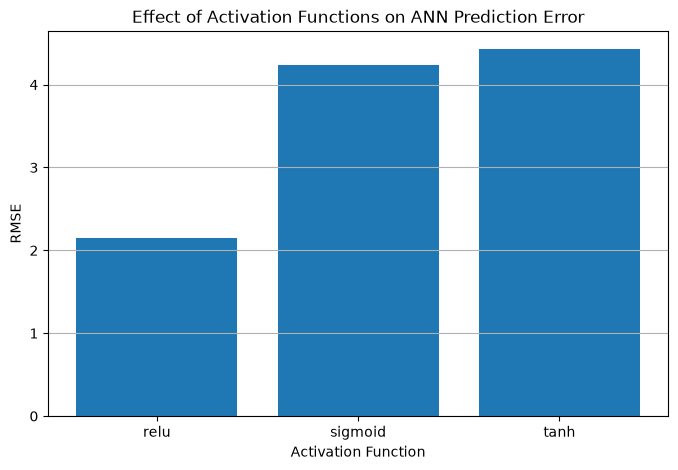

In [28]:
plt.figure(figsize=(8, 5))

plt.bar(
    activation_df['Activation'],
    activation_df['RMSE']
)

plt.xlabel("Activation Function")
plt.ylabel("RMSE")
plt.title("Effect of Activation Functions on ANN Prediction Error")
plt.grid(axis='y')

plt.savefig("ANN_Experiments/activation_vs_rmse.png", dpi=300)
plt.show()

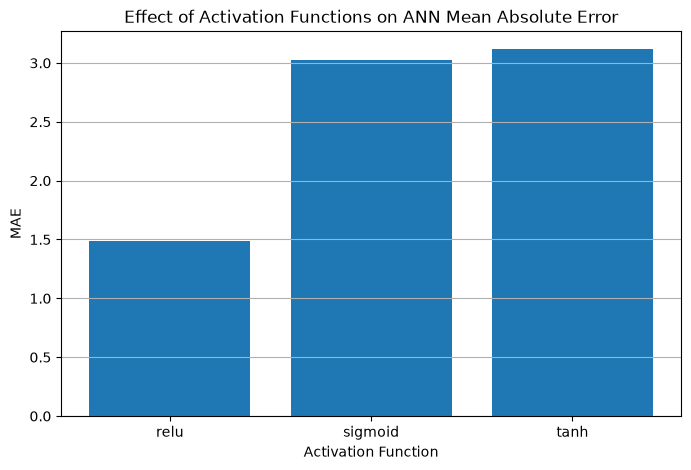

In [29]:
plt.figure(figsize=(8, 5))

plt.bar(
    activation_df['Activation'],
    activation_df['MAE']
)

plt.xlabel("Activation Function")
plt.ylabel("MAE")
plt.title("Effect of Activation Functions on ANN Mean Absolute Error")
plt.grid(axis='y')

plt.savefig("ANN_Experiments/activation_vs_mae.png", dpi=300)
plt.show()

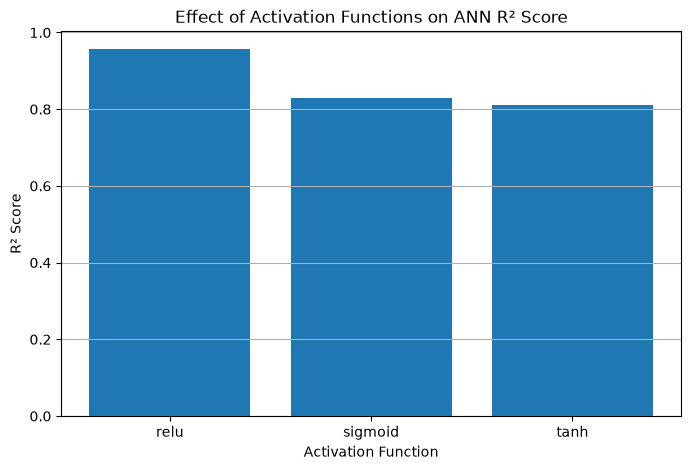

In [30]:
plt.figure(figsize=(8, 5))

plt.bar(
    activation_df['Activation'],
    activation_df['R2']
)

plt.xlabel("Activation Function")
plt.ylabel("R² Score")
plt.title("Effect of Activation Functions on ANN R² Score")
plt.grid(axis='y')

plt.savefig("ANN_Experiments/activation_vs_r2.png", dpi=300)
plt.show()

In [31]:
learning_rate_results = []

print("Ready for learning-rate experiments.")

Ready for learning-rate experiments.


In [32]:
learning_rates = [0.1, 0.01, 0.001, 0.0001]

for lr in learning_rates:

    print(f"Training ANN with learning rate {lr}...")

    model = build_ann(
        hidden_layers=2,
        activation='relu',
        learning_rate=lr
    )

    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True
    )

    start_time = time.time()

    model.fit(
        X_train_scaled,
        y_train,
        validation_split=0.2,
        epochs=100,
        batch_size=32,
        callbacks=[early_stop],
        verbose=0
    )

    execution_time = time.time() - start_time

    y_pred = model.predict(X_test_scaled, verbose=0).flatten()

    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)

    learning_rate_results.append({
        'Learning Rate': lr,
        'R2': r2,
        'RMSE': rmse,
        'MAE': mae,
        'Time (seconds)': execution_time
    })

print("All learning-rate experiments completed.")

Training ANN with learning rate 0.1...
Training ANN with learning rate 0.01...
Training ANN with learning rate 0.001...
Training ANN with learning rate 0.0001...
All learning-rate experiments completed.


In [33]:
learning_rate_df = pd.DataFrame(learning_rate_results)

learning_rate_df

,Learning Rate,R2,RMSE,MAE,Time (seconds)
0,0.1000,0.995917,0.652358,0.533181,14.507511
1,0.0100,0.986012,1.207463,0.965576,24.362557
2,0.0010,0.955274,2.159136,1.425538,23.479765
3,0.0001,0.719632,5.405849,3.625115,21.924308


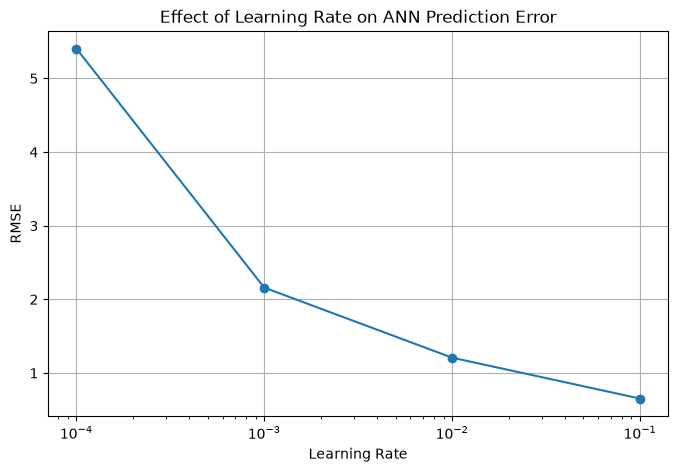

In [34]:
plt.figure(figsize=(8, 5))

plt.plot(
    learning_rate_df['Learning Rate'],
    learning_rate_df['RMSE'],
    marker='o'
)

plt.xlabel("Learning Rate")
plt.ylabel("RMSE")
plt.title("Effect of Learning Rate on ANN Prediction Error")
plt.xscale('log')
plt.grid(True)

plt.savefig("ANN_Experiments/learning_rate_vs_rmse.png", dpi=300)
plt.show()

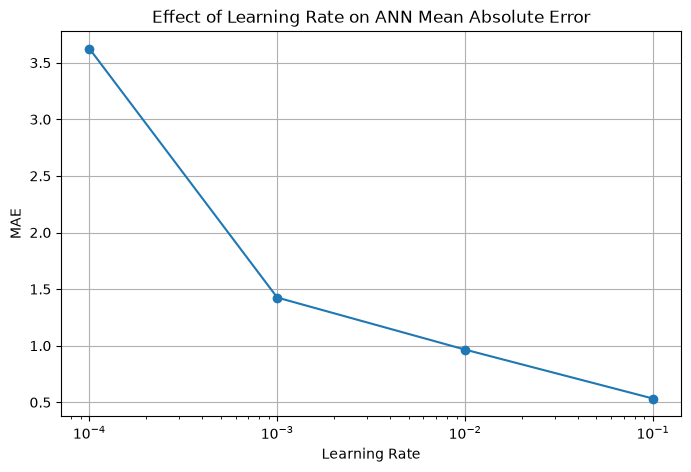

In [35]:
plt.figure(figsize=(8, 5))

plt.plot(
    learning_rate_df['Learning Rate'],
    learning_rate_df['MAE'],
    marker='o'
)

plt.xlabel("Learning Rate")
plt.ylabel("MAE")
plt.title("Effect of Learning Rate on ANN Mean Absolute Error")
plt.xscale('log')
plt.grid(True)

plt.savefig("ANN_Experiments/learning_rate_vs_mae.png", dpi=300)
plt.show()

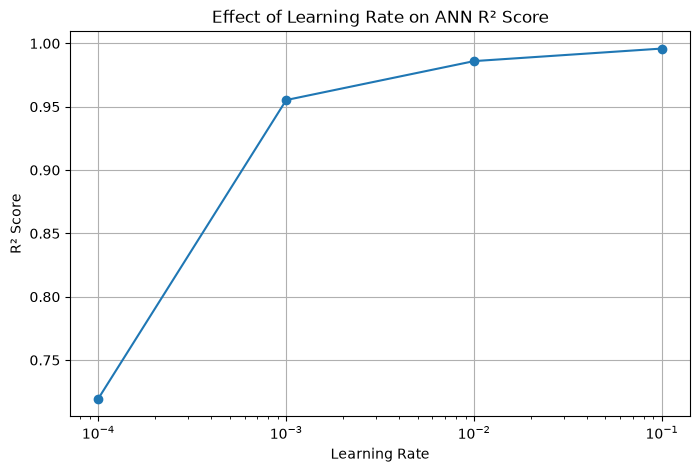

In [36]:
plt.figure(figsize=(8, 5))

plt.plot(
    learning_rate_df['Learning Rate'],
    learning_rate_df['R2'],
    marker='o'
)

plt.xlabel("Learning Rate")
plt.ylabel("R² Score")
plt.title("Effect of Learning Rate on ANN R² Score")
plt.xscale('log')
plt.grid(True)

plt.savefig("ANN_Experiments/learning_rate_vs_r2.png", dpi=300)
plt.show()

In [37]:
best_lr = learning_rate_df.loc[learning_rate_df['RMSE'].idxmin()]

print("Best Learning Rate Configuration:")
print(best_lr)

Best Learning Rate Configuration:
Learning Rate      0.100000
R2                 0.995917
RMSE               0.652358
MAE                0.533181
Time (seconds)    14.507511
Name: 0, dtype: float64


In [38]:
best_results = pd.DataFrame({
    'Parameter': ['Hidden Layers', 'Activation Function', 'Learning Rate'],
    'Best Configuration': ['5 Layers', 'ReLU', '0.1'],
    'R2': [0.995004, 0.955915, 0.995917],
    'RMSE': [0.721617, 2.143613, 0.652358],
    'MAE': [0.534064, 1.483034, 0.533181]
})

best_results.to_csv(
    "ANN_Experiments/Best_Parameter_Results.csv",
    index=False
)

best_results

,Parameter,Best Configuration,R2,RMSE,MAE
0,Hidden Layers,5 Layers,0.995004,0.721617,0.534064
1,Activation Function,ReLU,0.955915,2.143613,1.483034
2,Learning Rate,0.1,0.995917,0.652358,0.533181


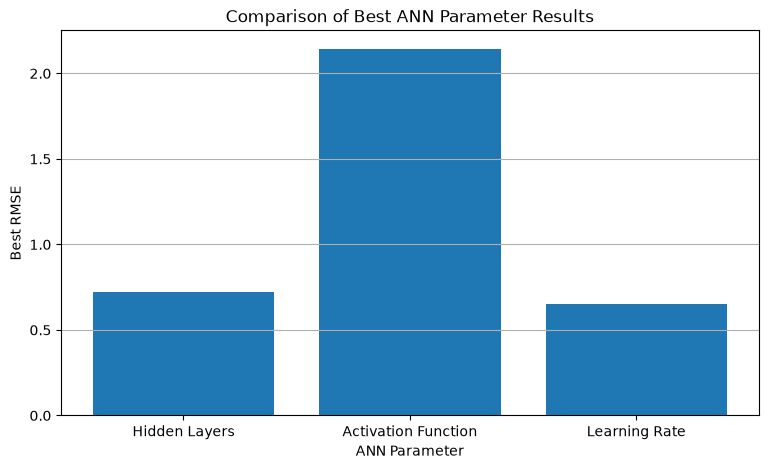

In [39]:
plt.figure(figsize=(9, 5))

plt.bar(
    best_results['Parameter'],
    best_results['RMSE']
)

plt.xlabel("ANN Parameter")
plt.ylabel("Best RMSE")
plt.title("Comparison of Best ANN Parameter Results")
plt.grid(axis='y')

plt.savefig(
    "ANN_Experiments/Best_Parameter_RMSE_Comparison.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

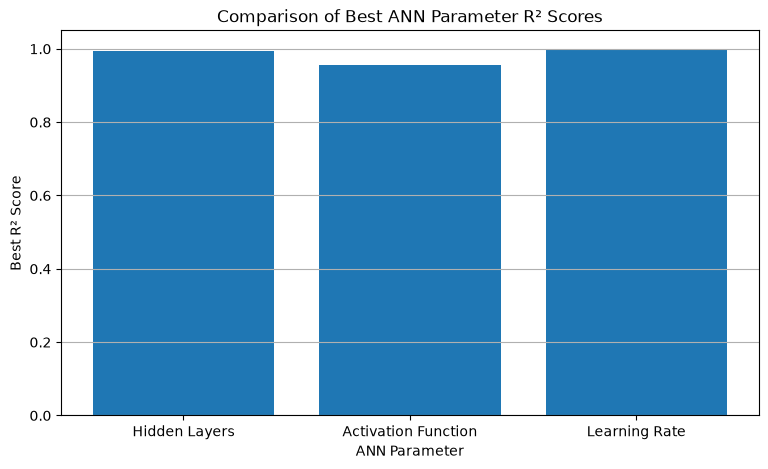

In [40]:
plt.figure(figsize=(9, 5))

plt.bar(
    best_results['Parameter'],
    best_results['R2']
)

plt.xlabel("ANN Parameter")
plt.ylabel("Best R² Score")
plt.title("Comparison of Best ANN Parameter R² Scores")
plt.ylim(0, 1.05)
plt.grid(axis='y')

plt.savefig(
    "ANN_Experiments/Best_Parameter_R2_Comparison.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

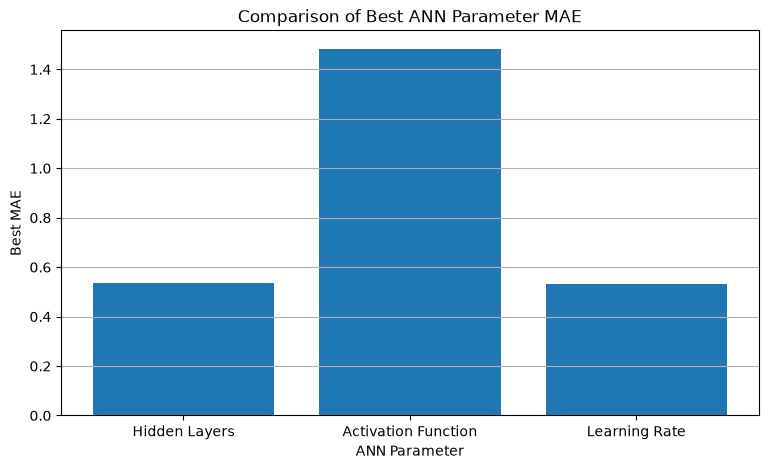

In [41]:
plt.figure(figsize=(9, 5))

plt.bar(
    best_results['Parameter'],
    best_results['MAE']
)

plt.xlabel("ANN Parameter")
plt.ylabel("Best MAE")
plt.title("Comparison of Best ANN Parameter MAE")
plt.grid(axis='y')

plt.savefig(
    "ANN_Experiments/Best_Parameter_MAE_Comparison.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [42]:
all_ann_results = pd.concat([
    hidden_df.assign(Experiment='Hidden Layers').rename(
        columns={'Hidden Layers': 'Configuration'}
    ),
    activation_df.assign(Experiment='Activation Function').rename(
        columns={'Activation': 'Configuration'}
    ),
    learning_rate_df.assign(Experiment='Learning Rate').rename(
        columns={'Learning Rate': 'Configuration'}
    )
], ignore_index=True)

all_ann_results.to_csv(
    "ANN_Experiments/All_ANN_Experiments.csv",
    index=False
)

print("Total configurations:", len(all_ann_results))
all_ann_results

Total configurations: 16


,Configuration,R2,RMSE,MAE,Time (seconds),Experiment
0,2,0.953326,2.205650,1.495393,22.480059,Hidden Layers
1,3,0.983505,1.311215,0.974448,24.416695,Hidden Layers
2,4,0.991731,0.928387,0.694709,24.798962,Hidden Layers
3,5,0.995004,0.721617,0.534064,24.478448,Hidden Layers
4,6,0.991831,0.922752,0.711123,22.239828,Hidden Layers
5,7,0.988068,1.115229,0.812153,17.184042,Hidden Layers
6,8,0.988026,1.117189,0.882174,19.868085,Hidden Layers
7,9,0.991256,0.954655,0.718482,20.210035,Hidden Layers
8,10,0.991164,0.959704,0.718056,22.581048,Hidden Layers
9,relu,0.955915,2.143613,1.483034,24.206327,Activation Function


In [43]:
final_ann = build_ann(
    hidden_layers=5,
    activation='relu',
    learning_rate=0.1
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

start_time = time.time()

final_history = final_ann.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

final_ann_time = time.time() - start_time

print("Final ANN training completed.")
print("Training time:", round(final_ann_time, 2), "seconds")

Epoch 1/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 112ms/step - loss: 639.6343 - mae: 22.9083 - val_loss: 509.1151 - val_mae: 20.4528
Epoch 2/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 532.9819 - mae: 20.7334 - val_loss: 438.9182 - val_mae: 18.6579
Epoch 3/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 449.4295 - mae: 18.6032 - val_loss: 330.3542 - val_mae: 15.4776
Epoch 4/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 272.1039 - mae: 13.1534 - val_loss: 116.5747 - val_mae: 8.2330
Epoch 5/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 110.5472 - mae: 9.0784 - val_loss: 112.5126 - val_mae: 9.3595
Epoch 6/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 109.0997 - mae: 9.4774 - val_loss: 90.8639 - val_mae: 8.5498
Epoch 7/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 104.6588 - mae: 9.1916 - val_loss: 91.3488 - val_mae: 8.6013
Epoch 8/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 103.4433 - mae: 9.2434 - val_loss: 92.6077 - val_mae: 8.6651
Epoch 9/100
16/16 ━

In [44]:
y_pred_final = final_ann.predict(X_test_scaled, verbose=0).flatten()

final_r2 = r2_score(y_test, y_pred_final)
final_rmse = np.sqrt(mean_squared_error(y_test, y_pred_final))
final_mae = mean_absolute_error(y_test, y_pred_final)

print("FINAL ANN PERFORMANCE")
print("----------------------")
print("R2 Score:", round(final_r2, 6))
print("RMSE:", round(final_rmse, 6))
print("MAE:", round(final_mae, 6))
print("Training Time:", round(final_ann_time, 2), "seconds")

FINAL ANN PERFORMANCE
----------------------
R2 Score: -0.017698
RMSE: 10.299331
MAE: 9.287644
Training Time: 7.02 seconds


In [45]:
stable_ann = build_ann(
    hidden_layers=5,
    activation='relu',
    learning_rate=0.001
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True
)

start_time = time.time()

stable_history = stable_ann.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=200,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

stable_time = time.time() - start_time

print("Stable ANN training completed.")
print("Training time:", round(stable_time, 2), "seconds")

Epoch 1/200
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 123ms/step - loss: 590.7586 - mae: 22.0823 - val_loss: 497.7509 - val_mae: 20.1883
Epoch 2/200
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 463.2827 - mae: 19.0019 - val_loss: 223.9184 - val_mae: 12.1196
Epoch 3/200
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 118.5967 - mae: 8.2282 - val_loss: 85.7798 - val_mae: 7.0892
Epoch 4/200
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 46.2467 - mae: 4.8152 - val_loss: 32.5804 - val_mae: 3.8421
Epoch 5/200
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 27.3275 - mae: 3.6743 - val_loss: 24.9658 - val_mae: 3.6603
Epoch 6/200
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 22.0044 - mae: 3.3824 - val_loss: 23.9267 - val_mae: 3.7591
Epoch 7/200
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 20.0964 - mae: 3.2008 - val_loss: 20.6929 - val_mae: 3.4485
Epoch 8/200
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 17.5450 - mae: 2.9910 - val_loss: 18.2863 - val_mae: 3.2278
Epoch 9/200
16/16 ━━━━━━━━━━━━

In [46]:
y_pred_stable = stable_ann.predict(
    X_test_scaled, verbose=0
).flatten()

stable_r2 = r2_score(y_test, y_pred_stable)
stable_rmse = np.sqrt(mean_squared_error(y_test, y_pred_stable))
stable_mae = mean_absolute_error(y_test, y_pred_stable)

print("STABLE ANN PERFORMANCE")
print("----------------------")
print("R2 Score:", round(stable_r2, 6))
print("RMSE:", round(stable_rmse, 6))
print("MAE:", round(stable_mae, 6))
print("Training Time:", round(stable_time, 2), "seconds")

STABLE ANN PERFORMANCE
----------------------
R2 Score: 0.994349
RMSE: 0.767504
MAE: 0.604282
Training Time: 26.6 seconds


In [47]:
stable_ann_results = pd.DataFrame({
    'Model': ['ANN'],
    'Hidden Layers': [5],
    'Neurons per Layer': [64],
    'Activation': ['ReLU'],
    'Learning Rate': [0.001],
    'R2': [stable_r2],
    'RMSE': [stable_rmse],
    'MAE': [stable_mae],
    'Training Time (seconds)': [stable_time]
})

stable_ann_results.to_csv(
    "ANN_Experiments/Stable_ANN_Final_Results.csv",
    index=False
)

stable_ann_results

,Model,Hidden Layers,Neurons per Layer,Activation,Learning Rate,R2,RMSE,MAE,Training Time (seconds)
0,ANN,5,64,ReLU,0.001,0.994349,0.767504,0.604282,26.599015


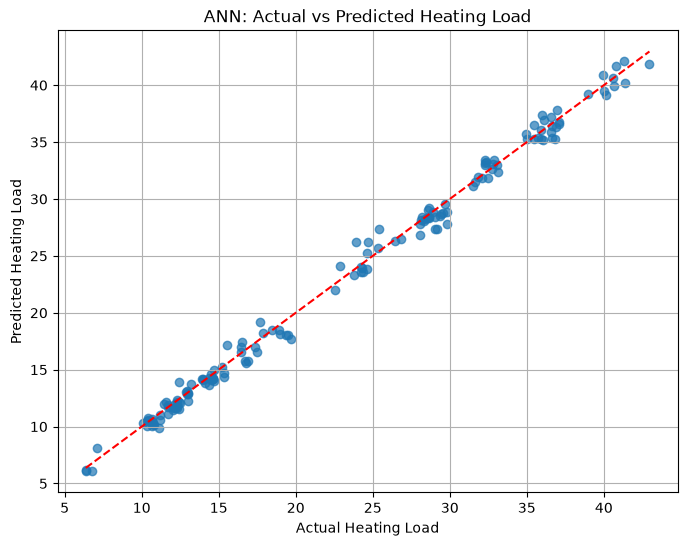

In [48]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_stable, alpha=0.7)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual Heating Load")
plt.ylabel("Predicted Heating Load")
plt.title("ANN: Actual vs Predicted Heating Load")
plt.grid(True)

plt.savefig(
    "ANN_Experiments/ANN_Actual_vs_Predicted.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

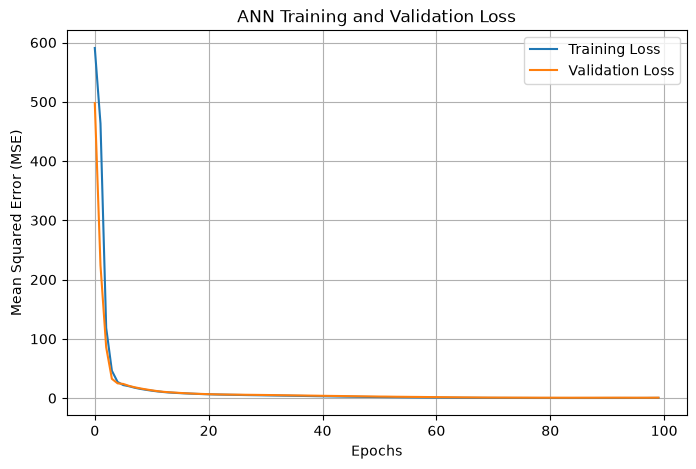

In [49]:
plt.figure(figsize=(8, 5))

plt.plot(stable_history.history['loss'], label='Training Loss')
plt.plot(stable_history.history['val_loss'], label='Validation Loss')

plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("ANN Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.savefig(
    "ANN_Experiments/ANN_Training_Validation_Loss.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [50]:
metric_names = [
    'mlr_r2', 'mlr_rmse', 'mlr_mae',
    'mlr_train_time', 'mlr_prediction_time',
    'knnr_r2', 'knnr_rmse', 'knnr_mae',
    'knnr_train_time', 'knnr_prediction_time'
]

for name in metric_names:
    if name in globals():
        print(name, "=", globals()[name])
    else:
        print(name, "= Not available")

mlr_r2 = Not available
mlr_rmse = Not available
mlr_mae = Not available
mlr_train_time = Not available
mlr_prediction_time = Not available
knnr_r2 = Not available
knnr_rmse = Not available
knnr_mae = Not available
knnr_train_time = Not available
knnr_prediction_time = Not available


In [51]:
print("MODEL-RELATED VARIABLES:")

for name in globals():
    if any(word in name.lower() for word in ['mlr', 'knn', 'model', 'pred']):
        print(name)

print("\nSAVED CSV FILES:")

for file in os.listdir("."):
    if file.endswith(".csv"):
        print(file)

MODEL-RELATED VARIABLES:
model
y_pred
y_pred_final
y_pred_stable

SAVED CSV FILES:
Building Energy Efficiency.csv
comparison_results.csv


In [52]:
comparison_df = pd.read_csv("comparison_results.csv")

print("Comparison Results:")
display(comparison_df)

Comparison Results:


,0,1,2,3,4,5,6
0,Heating Load,MLR,0.909259,3.075400,2.263105,0.025177,0.122502
1,Heating Load,KNNR,0.952007,2.236610,1.424905,0.032283,0.130198
2,Cooling Load,MLR,0.891785,3.166530,2.214961,0.013114,0.122142
3,Cooling Load,KNNR,0.931964,2.510779,1.615893,0.029039,0.129161


In [53]:
print("ANN Final Results:")
display(pd.read_csv("ANN_Experiments/Stable_ANN_Final_Results.csv"))

ANN Final Results:


,Model,Hidden Layers,Neurons per Layer,Activation,Learning Rate,R2,RMSE,MAE,Training Time (seconds)
0,ANN,5,64,ReLU,0.001,0.994349,0.767504,0.604282,26.599015


In [54]:
final_comparison = pd.DataFrame({
    "Model": ["MLR", "KNNR", "ANN"],
    "R2 Score": [0.909259, 0.952007, 0.994349],
    "RMSE": [3.075400, 2.236610, 0.767504],
    "MAE": [2.263105, 1.424905, 0.604282]
})

display(final_comparison)

final_comparison.to_csv(
    "ANN_Experiments/Final_Model_Comparison.csv",
    index=False
)

,Model,R2 Score,RMSE,MAE
0,MLR,0.909259,3.075400,2.263105
1,KNNR,0.952007,2.236610,1.424905
2,ANN,0.994349,0.767504,0.604282


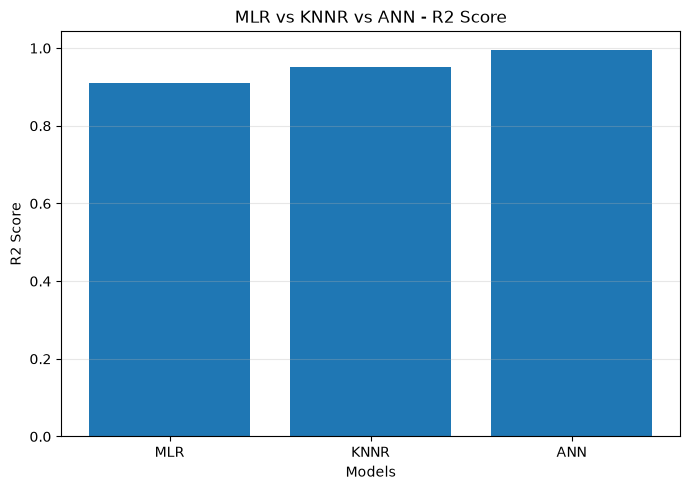

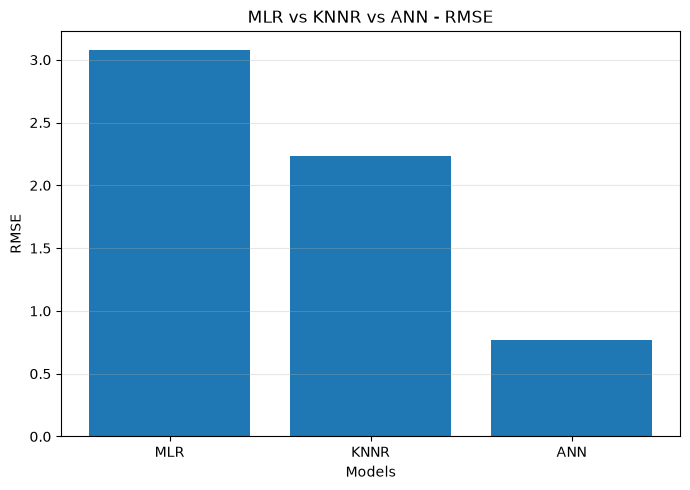

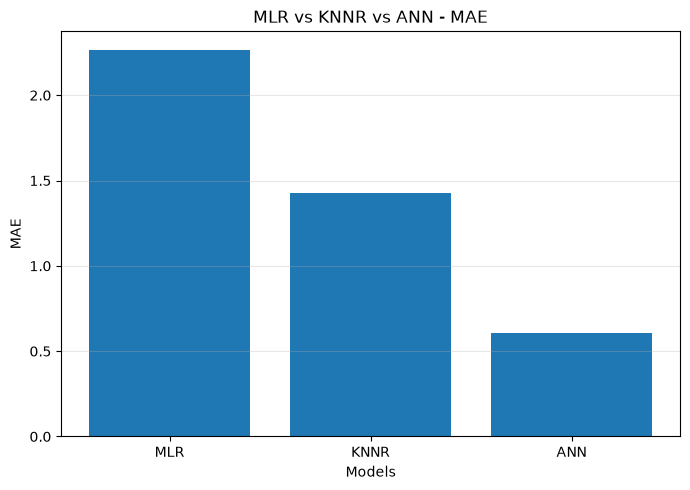

In [55]:
metrics = ["R2 Score", "RMSE", "MAE"]

for metric in metrics:
    plt.figure(figsize=(7, 5))
    plt.bar(final_comparison["Model"], final_comparison[metric])
    plt.title(f"MLR vs KNNR vs ANN - {metric}")
    plt.xlabel("Models")
    plt.ylabel(metric)
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        f"ANN_Experiments/Model_Comparison_{metric.replace(' ', '_')}.png",
        dpi=300
    )
    plt.show()
    

In [56]:
print("FILES IN ANN_Experiments FOLDER:\n")

for file in sorted(os.listdir("ANN_Experiments")):
    print(file)

FILES IN ANN_Experiments FOLDER:

.ipynb_checkpoints
ANN_Actual_vs_Predicted.png
ANN_Training_Validation_Loss.png
All_ANN_Experiments.csv
Best_Parameter_MAE_Comparison.png
Best_Parameter_R2_Comparison.png
Best_Parameter_RMSE_Comparison.png
Best_Parameter_Results.csv
Final_Model_Comparison.csv
Model_Comparison_MAE.png
Model_Comparison_R2_Score.png
Model_Comparison_RMSE.png
Stable_ANN_Final_Results.csv
activation_vs_mae.png
activation_vs_r2.png
activation_vs_rmse.png
hidden_layers_vs_mae.png
hidden_layers_vs_r2.png
hidden_layers_vs_rmse.png
learning_rate_vs_mae.png
learning_rate_vs_r2.png
learning_rate_vs_rmse.png


In [57]:
import shutil

shutil.copy(
    "comparison_results.csv",
    "ANN_Experiments/MLR_KNNR_Original_Results.csv"
)

print("MLR and KNNR results copied successfully!")

MLR and KNNR results copied successfully!


In [58]:
import shutil
import os

shutil.make_archive(
    "Building_Energy_ANN_Results",
    "zip",
    "ANN_Experiments"
)

print("ZIP file created successfully!")
print("File size:", round(
    os.path.getsize("Building_Energy_ANN_Results.zip") / (1024 * 1024), 2
), "MB")

ZIP file created successfully!
File size: 1.21 MB
